# Module scores, group distributions and confusion matrices

This tutorial covers three small but heavily used ArchR utilities and their Epione ports:

| ArchR | Epione | What it does |
|---|---|---|
| `addModuleScore` | `epi.tl.add_module_score` | per-cell score of a gene set, normalised against signal-matched background genes |
| `plotGroups` / `ggGroup` | `epi.pl.plot_groups` | ridge or violin plots of a per-cell value across groups |
| `confusionMatrix` | `epi.tl.confusion_matrix` (+ `epi.pl.plot_confusion_matrix`) | cross-tabulation of two labelings |

All three were rebuilt from the ArchR 1.0.3 source and checked number-for-number against ArchR on the
ArchR hematopoiesis tutorial data (BMMC, CD34+ BMMC and PBMC). The last section summarises that comparison.

## Load the data

We use the ArchR hematopoiesis tutorial data (Granja *et al.* 2019) processed with Epione only, as built in
the [ArchR hematopoiesis dataset](t_archr_heme_data) tutorial: fragments → QC → tile matrix → iterative LSI →
Leiden clusters → UMAP → gene scores (`epi.tl.add_gene_score_matrix`). Run that tutorial once and point
`EPIONE_ARCHR_HEME` at the directory it wrote. Any cells × genes AnnData with a grouping column works the same way.

In [1]:
import os, pathlib, warnings
warnings.filterwarnings('ignore', category=DeprecationWarning)
import numpy as np
import pandas as pd
import anndata as ad
import matplotlib.pyplot as plt
from IPython.display import display
import epione as epi

DATA = pathlib.Path(os.environ.get('EPIONE_ARCHR_HEME', 'data_archr_heme'))

adata = ad.read_h5ad(DATA / 'heme_gene_scores.h5ad')      # cells x genes (gene scores)
adata.obs['UMAP1'], adata.obs['UMAP2'] = adata.obsm['X_umap'][:, 0], adata.obsm['X_umap'][:, 1]
cluster_order = sorted(adata.obs['Clusters'].unique(), key=lambda s: int(s[1:]))
adata

AnnData object with n_obs × n_vars = 10705 × 20057
    obs: 'Sample', 'n_fragment', 'tsse', 'Clusters', 'UMAP1', 'UMAP2'
    var: 'chrom', 'start', 'end', 'strand'
    uns: 'files'
    obsm: 'X_iterative_lsi', 'X_umap'

## Confusion matrix

`epi.tl.confusion_matrix(i, j)` counts cells for every pair of labels. Rows and columns keep the order in which
labels first appear, exactly like ArchR's `confusionMatrix`. Here we ask which samples contribute to each cluster.

In [2]:
cm = epi.tl.confusion_matrix(adata.obs['Clusters'], adata.obs['Sample'])
cm

,scATAC_BMMC_R1,scATAC_CD34_BMMC_R1,scATAC_PBMC_R1
C9,431,8,0
C1,1423,17,1034
C8,287,7,182
C5,222,718,3
C2,1399,1,166
C3,519,797,8
C10,184,211,15
C4,119,1163,0
C6,316,4,587
C7,29,11,471


The ArchR tutorial normalises each row to fractions before plotting. `epi.pl.plot_confusion_matrix` does that with
`normalize='row'` and uses ArchR's `whiteBlue` colours. The table lists the dominant sample of each cluster;
progenitor clusters come mostly from the CD34+ sample.

,C1,C2,C3,C4,C5,C6,C7,C8,C9,C10,C11
dominant sample,scATAC_BMMC_R1,scATAC_BMMC_R1,scATAC_CD34_BMMC_R1,scATAC_CD34_BMMC_R1,scATAC_CD34_BMMC_R1,scATAC_PBMC_R1,scATAC_PBMC_R1,scATAC_BMMC_R1,scATAC_BMMC_R1,scATAC_CD34_BMMC_R1,scATAC_CD34_BMMC_R1
fraction,0.58,0.89,0.6,0.91,0.76,0.65,0.92,0.6,0.98,0.51,0.95


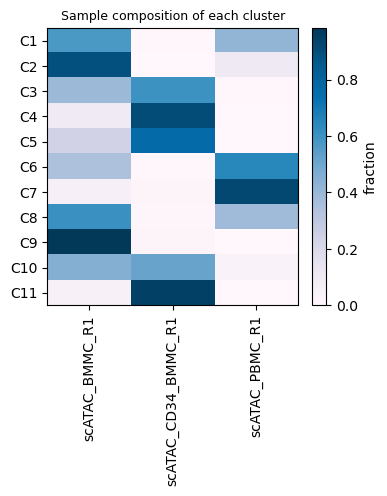

In [3]:
frac = cm.div(cm.sum(axis=1), axis=0).loc[cluster_order]
display(pd.DataFrame({'dominant sample': frac.idxmax(axis=1), 'fraction': frac.max(axis=1).round(2)}).T)
fig = epi.pl.plot_confusion_matrix(cm.loc[cluster_order], normalize='row', figsize=(3.6, 3.6))
fig.axes[0].set_title('Sample composition of each cluster', fontsize=9)
plt.show()

## Module scores

A module score summarises a gene set in one number per cell:

$$\text{score}_c = \frac{1}{|F|}\sum_{f\in F} x_{fc} \;-\; \frac{1}{|B|}\sum_{b\in B} x_{bc}$$

where $F$ are the module genes and $B$ the background genes. All genes are ranked by total signal and cut into
`n_bin` equal-size bins (genes with zero signal form bin 0). For every module gene, `n_bgd` background genes are drawn
from the matching signal bin, so the background has the same overall signal level as the module.
`n_bgd` must be smaller than the smallest bin; here the zero-signal bin is small, so we use `n_bgd=50`
instead of ArchR's default 100.

Two details matter for exact agreement with ArchR:

* **Sampling** uses an exact emulation of R's random number generator, so `seed=1` draws the same background genes
  as ArchR's `seed = 1`.
* **Gene totals.** ArchR ranks genes by the row sums it stored per sample (one Arrow file per sample). Passing
  `sample_key='Sample'` reproduces those sums bit for bit. Without it, floating-point rounding can reorder a handful
  of near-tied genes, so a few background genes differ (the scores still correlate at r > 0.999).

In [4]:
modules = {
    'B': ['MS4A1', 'CD79A', 'PAX5'],
    'T': ['CD3D', 'CD3E', 'CD2'],
    'Mono': ['CD14', 'LYZ', 'CEBPB'],
    'Erythroid': ['GATA1', 'KLF1', 'HBB'],
    'Progenitor': ['CD34'],
}
scores = epi.tl.add_module_score(adata, modules, n_bin=25, n_bgd=50, seed=1, sample_key='Sample')
scores.head()

Module.B: 3 features, 150 background features
Module.Erythroid: 3 features, 150 background features


Module.Mono: 3 features, 150 background features
Module.Progenitor: 1 features, 50 background features


Module.T: 3 features, 150 background features


,Module.B,Module.T,Module.Mono,Module.Erythroid,Module.Progenitor
scATAC_BMMC_R1#AAACGAAAGCACGTAG-1,-0.060296,-0.762423,-1.293425,-0.581702,-0.867448
scATAC_BMMC_R1#AAACGAAAGGCCAGTA-1,-0.184204,-0.479996,-0.630284,-0.404307,-0.849919
scATAC_BMMC_R1#AAACGAAAGGTTGTTC-1,6.610682,1.028961,-1.347666,-0.493373,-1.156241
scATAC_BMMC_R1#AAACGAAGTCTGCGCA-1,-0.623381,1.801084,-0.818269,-0.282470,-0.676602
scATAC_BMMC_R1#AAACGAAGTGATGCTT-1,0.458329,-0.397715,-0.868316,-0.545441,-0.634028


Mean score per cluster, and the cluster where each module peaks. Lineage modules (B, T, monocyte, erythroid,
CD34+ progenitor) are highest in the clusters of the matching cell types; the UMAPs below show the same pattern
per cell.

In [5]:
summary = scores.groupby(adata.obs['Clusters'].astype(str).values).mean().loc[cluster_order]
display(summary.round(2).style.background_gradient(cmap='RdBu_r', axis=0))
print('top cluster per module:', summary.idxmax().to_dict())

,Module.B,Module.T,Module.Mono,Module.Erythroid,Module.Progenitor
C1,-0.250000,-0.240000,1.480000,0.010000,0.130000
C2,-0.000000,0.890000,0.100000,0.170000,-0.120000
C3,0.030000,-0.170000,0.480000,-0.000000,0.460000
C4,0.030000,-0.100000,0.120000,0.020000,0.450000
C5,-0.050000,-0.170000,0.170000,0.480000,0.370000
C6,-0.060000,0.490000,-0.020000,0.100000,-0.270000
C7,-0.080000,0.420000,0.040000,0.150000,-0.160000
C8,1.330000,-0.250000,-0.110000,0.110000,-0.140000
C9,0.930000,-0.230000,-0.130000,-0.090000,0.060000
C10,0.040000,-0.020000,-0.130000,-0.150000,0.210000


top cluster per module: {'Module.B': 'C8', 'Module.T': 'C2', 'Module.Mono': 'C1', 'Module.Erythroid': 'C5', 'Module.Progenitor': 'C3'}


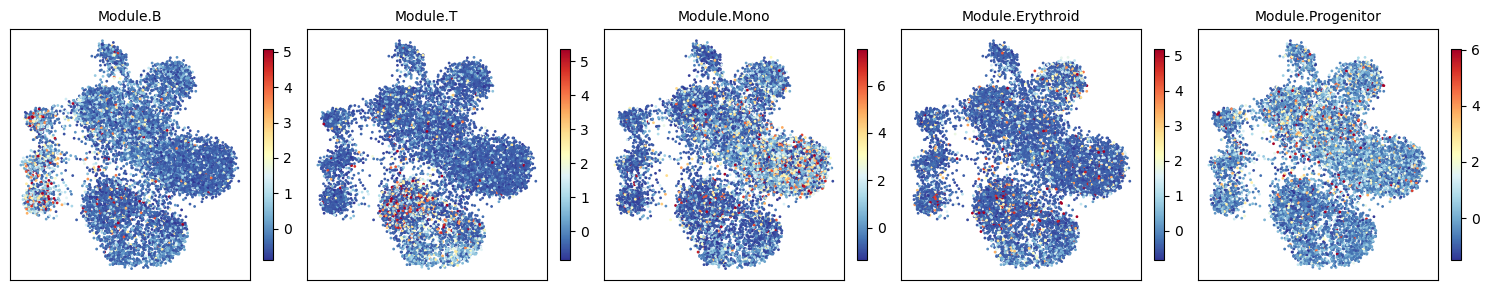

In [6]:
fig, axes = plt.subplots(1, 5, figsize=(15, 3))
for ax, col in zip(axes, scores.columns):
    v = scores[col].values
    lo, hi = np.quantile(v, [0.01, 0.99])
    sc = ax.scatter(adata.obs['UMAP1'], adata.obs['UMAP2'], c=np.clip(v, lo, hi), s=1,
                    cmap='RdYlBu_r', rasterized=True)
    ax.set_title(col, fontsize=10); ax.set_xticks([]); ax.set_yticks([])
    fig.colorbar(sc, ax=ax, fraction=0.04)
plt.tight_layout(); plt.show()

Parameters and the background genes that were drawn are stored in `adata.uns['module_score']`:

In [7]:
info = adata.uns['module_score']
print(info['params'])
print('B module genes      :', info['features']['Module.B'])
print('first 10 background :', info['background']['Module.B'][:10])

{'n_bin': 25, 'n_bgd': 50, 'seed': 1, 'layer': None, 'sample_key': 'Sample', 'archr_bin_indexing': True}
B module genes      : ['MS4A1', 'CD79A', 'PAX5']
first 10 background : ['FABP12', 'OR5H6', 'HAVCR1', 'POU1F1', 'CYP2J2', 'CFB', 'OR8B12', 'COQ3', 'CALCRL', 'CELA3A']


### ArchR 1.0.3 behaviours worth knowing

Porting from source turned up three behaviours of ArchR 1.0.3's `addModuleScore` for gene-name modules:

1. **Background bin offset.** ArchR looks up each gene's background pool with `binList[bin]`, which indexes the list
   *by position*. When genes with zero signal exist (counted below), position `k` holds bin `k-1`, so background genes come
   from the next-lower signal bin. Epione reproduces this by default (`archr_bin_indexing=True`) and offers
   `archr_bin_indexing=False` to sample from the gene's own bin.
2. **Several multi-gene modules in one call** fail (`5 elements in value to replace 13`) or, when the gene count is a
   multiple of the module count, silently assign genes to the wrong module. Epione assigns every gene to its own module.
3. **One-gene modules** (like `Progenitor = CD34`) fail in ArchR with a `colMeans` error. Epione handles them.

In all cases where ArchR runs correctly, the Epione result is identical; for 2 and 3 the comparison used ArchR with a
two-token fix (see the parity section).

In [8]:
n_zero = int((np.asarray(adata.X.sum(axis=0)).ravel() == 0).sum())
print(f'genes with zero total signal: {n_zero}')
own_bin = epi.tl.add_module_score(adata, modules, n_bin=25, n_bgd=50, seed=1, sample_key='Sample', archr_bin_indexing=False,
                                  inplace=False, verbose=False)
print('Pearson r, ArchR-style vs own-bin background:')
print(pd.Series({c: np.corrcoef(scores[c], own_bin[c])[0, 1] for c in scores.columns}).round(4))

genes with zero total signal: 87


Pearson r, ArchR-style vs own-bin background:
Module.B             0.9860
Module.T             0.9894
Module.Mono          0.9875
Module.Erythroid     0.9851
Module.Progenitor    0.9639
dtype: float64


## Group distributions with `plot_groups`

`epi.pl.plot_groups` draws one distribution per group for an `obs` column or a gene. It follows ArchR's `plotGroups`
step by step:

* each group is down-sampled to `max_cells` (1000) cells with R-compatible sampling (`seed=1` = `set.seed(1)`),
* values are clipped to the 0.2-99.8 % quantiles of the sampled cells (`quant_cut`),
* ridge plots order groups by reverse "mixed" sort (C11 ... C2, C1); violins by mixed sort,
* colours follow ArchR's `stallion` palette.

TSS enrichment (`tsse`) per sample, as ridges:

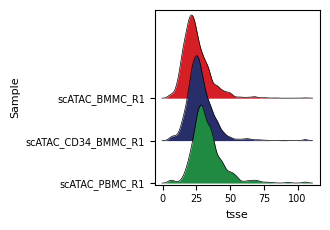

In [9]:
fig = epi.pl.plot_groups(adata, group_by='Sample', name='tsse', plot_as='ridges', figsize=(3.4, 2.4))
plt.show()

Gene scores per cluster. As in ArchR, several genes can be passed at once; the same sampled cells are used for all of them.

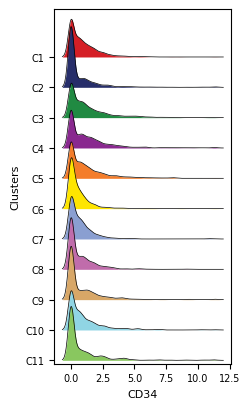

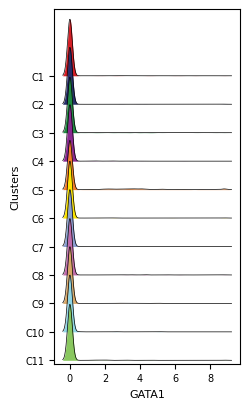

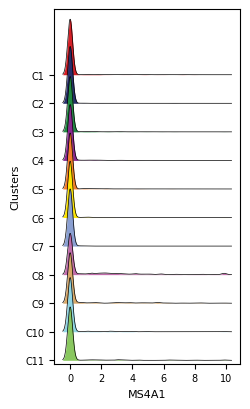

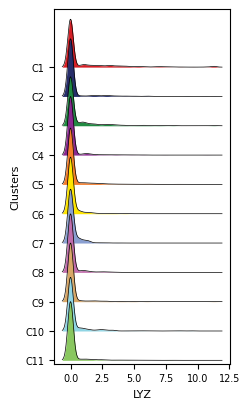

In [10]:
figs = epi.pl.plot_groups(adata, group_by='Clusters', name=['CD34', 'GATA1', 'MS4A1', 'LYZ'], plot_as='ridges',
                          figsize=(2.6, 4.2))
plt.show()

Violin + box plots of the module scores:

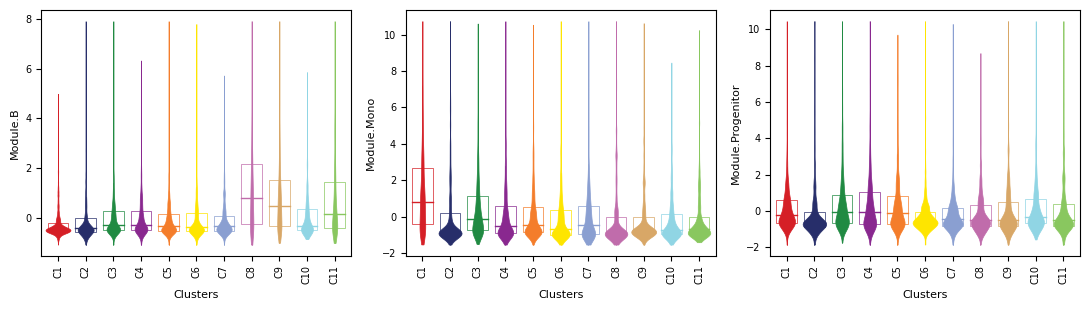

In [11]:
fig, axes = plt.subplots(1, 3, figsize=(11, 3.2))
for ax, col in zip(axes, ['Module.B', 'Module.Mono', 'Module.Progenitor']):
    epi.pl.plot_groups(adata, group_by='Clusters', name=col, plot_as='violin', ax=ax)
plt.tight_layout(); plt.show()

`return_data=True` gives the numbers behind a plot: the sampled cells, the clipped values, the group order, and the
density / box statistics that were drawn.

In [12]:
fig, d = epi.pl.plot_groups(adata, group_by='Clusters', name='Module.T', plot_as='violin', return_data=True)
plt.close(fig)
display(d['box'].round(3))

,group,x,ymin,lower,middle,upper,ymax,n
0,C1,1,-0.869,-0.540,-0.441,-0.309,0.034,1000
1,C2,2,-1.040,-0.492,-0.243,1.645,4.814,1000
2,C3,3,-1.002,-0.547,-0.441,-0.197,0.326,1000
3,C4,4,-1.040,-0.535,-0.433,-0.181,0.343,1000
4,C5,5,-1.040,-0.547,-0.432,-0.162,0.408,943
5,C6,6,-1.032,-0.437,0.014,1.045,3.229,907
6,C7,7,-1.040,-0.410,0.115,0.898,2.731,511
7,C8,8,-0.903,-0.560,-0.456,-0.327,0.021,476
8,C9,9,-0.901,-0.558,-0.454,-0.315,0.024,439
9,C10,10,-0.818,-0.536,-0.391,0.097,1.021,410


## Parity vs ArchR

Every function was compared with ArchR 1.0.3 (R 4.4.3, ggplot2 4.0.3, ggridges 0.5.7) on the ArchR project of this
dataset (10,660 cells, 23,127-gene `GeneScoreMatrix`), feeding both tools the same inputs. Thresholds were registered
in `tests/parity/module_score_groups/MANIFEST.md` before the first comparison and never loosened.

| Output | Class | Gate | Value |
|---|---|---|---|
| `confusionMatrix` counts + row/column order | 1 strict | == 0 | 0 (identical order) |
| gene totals with `sample_key="Sample"` vs ArchR's Arrow `rowSums` | 1 strict | bitwise | identical |
| background genes, free-running (10 configurations) | 1 strict | identical | identical |
| module scores, ArchR's background draws injected | 1 | ≤ 1e-8 | 3.6e-14 |
| module scores, free-running `seed` | 1 | ≤ 1e-8 | 3.6e-14 |
| `plotGroups` sampled cells / groups / order (10 cases) | 1 strict | identical | identical |
| `plotGroups` values after `quantCut` | 1 | ≤ 1e-8 | 2.8e-14 |
| ridge / violin densities | 1 bounded | ≤ 1e-6 | 5.9e-14 |
| box statistics | 1 | ≤ 1e-8 | 1.8e-15 |

Free-running results are exact because sampling uses a bit-exact emulation of R's random number generator
(`epione.core._r_random`). Module-score references were taken from unmodified ArchR (one call per multi-gene module)
and from ArchR with its two module-assignment bugs fixed (all modules in one call); where both run they agree exactly.
The only non-exact mode is calling `add_module_score` without `sample_key`: gene totals are then summed over all
cells at once and last-bit rounding changes the rank of a few near-tied genes (min Pearson 0.9996).

The ArchR reference outputs are generated outside this repository. With them available, the comparison is rerun by
`tests/parity/module_score_groups/py_parity.py` and `tests/test_module_score_groups.py`, which read
`$EPIONE_ARCHR_PARITY_DIR/module_score_groups/` and are skipped otherwise.